Câu 1: Thêm tên các cột theo thứ tự id, device_id, co_level, humidity, temperature và time.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 1 (Trang 30)")

df = pd.read_excel("data/tb_tracking.xlsx", header=None)

print("\nNăm dòng đầu trước khi thêm tên cột")
print(df.head().to_string(index=False, header=False))

df.columns = [
    "id", "device_id", "co_level",
    "humidity", "temperature", "time"
]

print("\nNăm dòng đầu sau khi thêm tên cột")
print(df.head().to_string(index=False))

print("\nKích thước dữ liệu đọc từ Excel")
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

print("\nKiểu dữ liệu của các thuộc tính")
print(df.dtypes)

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 1 (Trang 30)

Năm dòng đầu trước khi thêm tên cột
1.0   1.0 2.0 3.0   4.0 2016-12-20 12:52:29
2.0   1.0 2.0 3.0   4.0 2016-12-20 12:52:31
3.0 100.0 2.0 3.0   4.0 2016-12-20 12:52:35
4.0 100.0 2.0 3.0 400.0 2016-12-20 12:52:37
5.0   1.0 2.0 3.0   4.0 2016-12-20 13:02:01

Năm dòng đầu sau khi thêm tên cột
 id  device_id  co_level  humidity  temperature                time
1.0        1.0       2.0       3.0          4.0 2016-12-20 12:52:29
2.0        1.0       2.0       3.0          4.0 2016-12-20 12:52:31
3.0      100.0       2.0       3.0          4.0 2016-12-20 12:52:35
4.0      100.0       2.0       3.0        400.0 2016-12-20 12:52:37
5.0        1.0       2.0       3.0          4.0 2016-12-20 13:02:01

Kích thước dữ liệu đọc từ Excel
Số dòng: 33340
Số cột: 6

Kiểu dữ liệu của các thuộc tính
id                    float64
device_id             float64
co_level              float64
humidity              float64
temperature       

- Nhận xét: Dữ liệu đã được bổ sung đầy đủ 6 tên cột theo yêu cầu. File Excel có 33.340 dòng, trong đó cuối bảng có một dòng trống và ba dòng thống kê, không phải bản ghi đo.

Câu 2: Loại bỏ dữ liệu trước ngày 03/01/2018 do cảm biến chỉ đo chính xác từ ngày này.

In [2]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 2 (Trang 30)")

du_lieu_cau2 = df.copy()

vi_tri_dong_trong = du_lieu_cau2.index[
    du_lieu_cau2.isna().all(axis=1)
]
if len(vi_tri_dong_trong) > 0:
    du_lieu_cau2 = du_lieu_cau2.iloc[:vi_tri_dong_trong[0]].copy()

so_ban_ghi_ban_dau = len(du_lieu_cau2)

du_lieu_cau2["time"] = pd.to_datetime(
    du_lieu_cau2["time"], errors="coerce"
)
ngay_bat_dau = pd.Timestamp(year=2018, month=1, day=3)
du_lieu_cau2 = du_lieu_cau2.loc[
    du_lieu_cau2["time"] >= ngay_bat_dau
].copy()

du_lieu_cau2 = du_lieu_cau2.reset_index(drop=True)

print("\nSố bản ghi đo ban đầu:", so_ban_ghi_ban_dau)
print("Số bản ghi bị loại:", so_ban_ghi_ban_dau - len(du_lieu_cau2))
print("Số bản ghi còn lại:", len(du_lieu_cau2))

print("\nThời điểm đo đầu tiên sau khi lọc:", du_lieu_cau2["time"].min())
print("Thời điểm đo cuối cùng sau khi lọc:", du_lieu_cau2["time"].max())

print("\nNăm dòng dữ liệu sau khi lọc")
print(du_lieu_cau2.head().to_string(index=False))

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 2 (Trang 30)

Số bản ghi đo ban đầu: 33336
Số bản ghi bị loại: 31419
Số bản ghi còn lại: 1917

Thời điểm đo đầu tiên sau khi lọc: 2018-01-03 13:11:07
Thời điểm đo cuối cùng sau khi lọc: 2018-01-17 15:46:34

Năm dòng dữ liệu sau khi lọc
     id  device_id  co_level  humidity  temperature                time
31420.0        1.0       2.0       3.0          4.0 2018-01-03 13:11:07
31421.0        1.0       2.0       3.0          4.0 2018-01-03 13:15:10
31422.0    99005.0      58.0      26.0          0.0 2018-01-03 13:17:30
31423.0    99005.0      58.0      26.0          0.0 2018-01-03 13:19:21
31424.0    99005.0      58.0      26.0          0.0 2018-01-03 13:24:17


- Nhận xét: Sau khi loại các dòng thống kê cuối bảng và chỉ giữ dữ liệu từ ngày 03/01/2018, còn 1.917 bản ghi đo hợp lệ theo mốc thời gian của đề.

Câu 3: Từ cột time, tạo thuộc tính minutes biểu diễn thời điểm đo trong ngày tính theo phút.

In [3]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 3 (Trang 30)")

du_lieu_cau3 = du_lieu_cau2.copy()
du_lieu_cau3["minutes"] = (
    du_lieu_cau3["time"].dt.hour * 60
    + du_lieu_cau3["time"].dt.minute
    + du_lieu_cau3["time"].dt.second / 60
)

du_lieu_cau3["minutes"] = du_lieu_cau3["minutes"].round(2)

print("\nDữ liệu thời điểm đo và số phút trong ngày")
print(du_lieu_cau3[["time", "minutes"]].head(10).to_string(index=False))

print("\nThống kê thuộc tính minutes")
print(du_lieu_cau3["minutes"].describe())

print("\nSố giá trị thiếu ở thuộc tính minutes:",
      du_lieu_cau3["minutes"].isna().sum())

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 3 (Trang 30)

Dữ liệu thời điểm đo và số phút trong ngày
               time  minutes
2018-01-03 13:11:07   791.12
2018-01-03 13:15:10   795.17
2018-01-03 13:17:30   797.50
2018-01-03 13:19:21   799.35
2018-01-03 13:24:17   804.28
2018-01-03 13:29:13   809.22
2018-01-03 13:34:10   814.17
2018-01-03 14:05:34   845.57
2018-01-03 14:10:43   850.72
2018-01-03 14:15:39   855.65

Thống kê thuộc tính minutes
count    1917.000000
mean      709.793798
std       391.935479
min         1.500000
25%       396.180000
50%       713.480000
75%       993.420000
max      1439.000000
Name: minutes, dtype: float64

Số giá trị thiếu ở thuộc tính minutes: 0


- Nhận xét: Thuộc tính minutes thể hiện số phút tính từ 00:00 của từng ngày, được tính từ giờ, phút và giây trong cột time. Thuộc tính mới giúp khảo sát dữ liệu theo thời điểm đo trong ngày.

Câu 4: Vẽ đồ thị phân tán lần lượt thể hiện nồng độ khí CO, độ ẩm và nhiệt độ theo thuộc tính minutes.

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 4 (Trang 30)


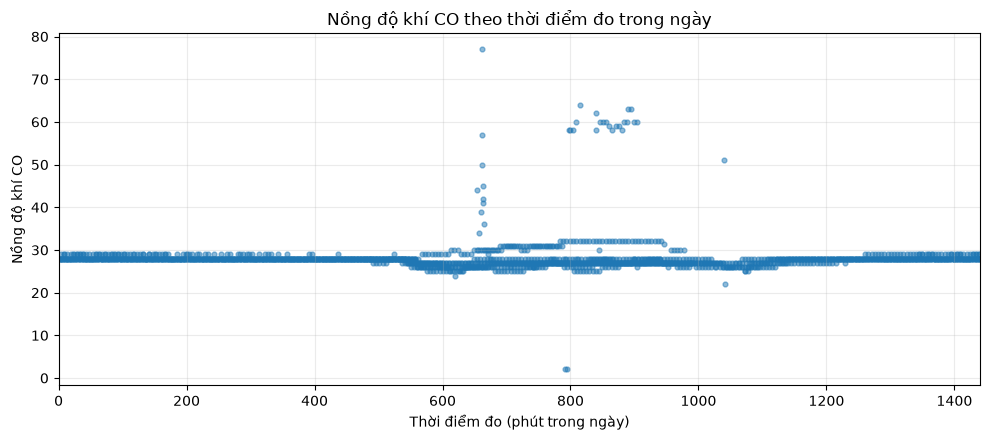

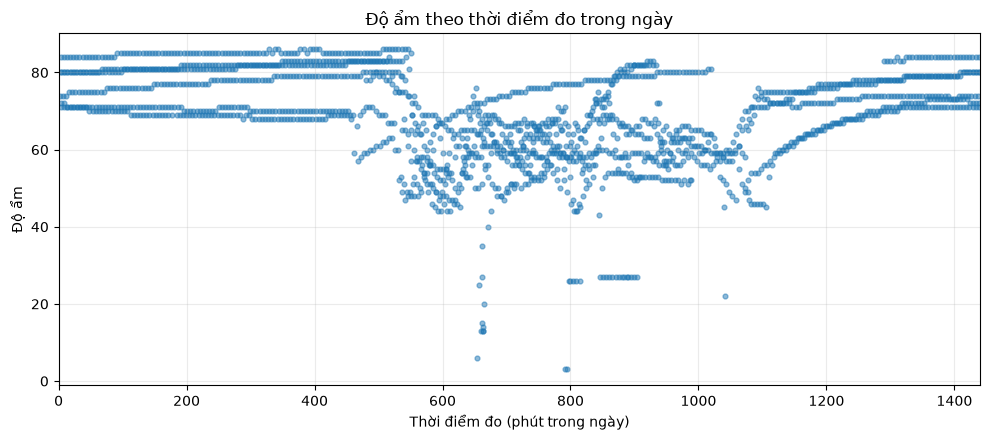

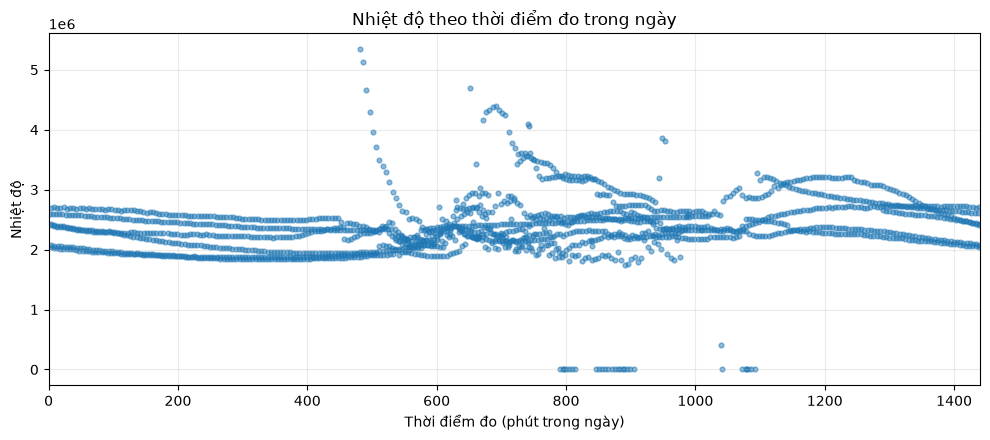


Giá trị nhỏ nhất và lớn nhất của các thuộc tính
     co_level  humidity  temperature
min       2.0       3.0          0.0
max      77.0      86.0    5340310.0


In [4]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 4 (Trang 30)")

du_lieu_cau4 = du_lieu_cau3.copy()

cac_thuoc_tinh = [
    ("co_level", "Nồng độ khí CO"),
    ("humidity", "Độ ẩm"),
    ("temperature", "Nhiệt độ")
]

for cot, ten_thuoc_tinh in cac_thuoc_tinh:
    plt.figure(figsize=(10, 4.5))
    plt.scatter(
        du_lieu_cau4["minutes"],
        du_lieu_cau4[cot],
        s=12,
        alpha=0.5
    )
    plt.title(f"{ten_thuoc_tinh} theo thời điểm đo trong ngày")
    plt.xlabel("Thời điểm đo (phút trong ngày)")
    plt.ylabel(ten_thuoc_tinh)
    plt.xlim(0, 1440)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

print("\nGiá trị nhỏ nhất và lớn nhất của các thuộc tính")
print(du_lieu_cau4[["co_level", "humidity", "temperature"]].agg(["min", "max"]))

- Nhận xét: Ba biểu đồ phân tán thể hiện sự phân bố các giá trị CO, độ ẩm và nhiệt độ theo số phút trong ngày. Thuộc tính nhiệt độ có những giá trị rất lớn so với phần còn lại, làm thay đổi tỷ lệ trục tung; cần kiểm tra các giá trị bất thường nếu tiếp tục phân tích chuyên sâu.